In [2]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline 
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(seed=223)


[ 4  7  3 10  1  6  2 11 12  5  8  9  0]


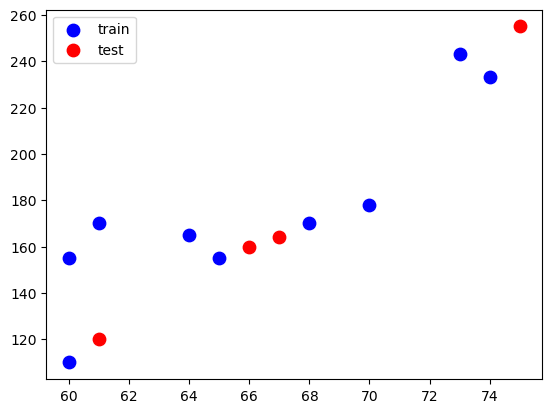

In [3]:
x = np.array([66,  68, 60,   70,  65,  61,  74,  73,  75,  67,  60,  61,  64,    77])
y = np.array([160, 170, 110, 178, 155, 120, 233, 243, 255, 164, 155,  170, 165, 200])
ids = np.random.permutation(range(0,len(x)-1))
print(ids)
id_train = ids[0:9]
id_test = ids[9:]
xtrain = x[id_train]
xtest  = x[id_test]
ytrain = y[id_train]
ytest = y[id_test]
#plot data and mean
plt.scatter(xtrain,ytrain, s=80, c="blue",label='train')
plt.scatter(xtest,ytest, s=80, c="red",label='test')
plt.legend()
plt.show()


## Models

Here we consider four different models:
$$
m_1(x_i;\theta) = \theta_0+\theta_1 x_i 
$$
$$
m_2(x_i;\theta) = \theta_0+\theta_1 x_i +\theta_2 x_i^2  
$$
$$
m_3(x_i;\theta) = \theta_0+\theta_1 x_i +\theta_2 x_i^2 +\theta_3 x_i^3
$$
$$
m_4(x_i;\theta) = \theta_0+\theta_1 x_i +\theta_2 x_i^2 +\theta_3 x_i^3 +\theta_4 x_i^4
$$

These models can all be written as $X\theta$, but the size of $X$ and $\theta$ and their structure will be different.

In [4]:
# Lets consider four different models
Xones = np.ones(shape=(len(xtrain)))
X1 = np.c_[Xones[:],xtrain]
X2 = np.c_[Xones[:],xtrain,xtrain**2]
X3 = np.c_[Xones[:],xtrain,xtrain**2,xtrain**3]
X4 = np.c_[Xones[:],xtrain,xtrain**2,xtrain**3,xtrain**4]


### We can solve each of these by using the normal equations

In [5]:
theta_1 = np.linalg.inv(X1.T@X1)@(X1.T@ytrain)
theta_2 = np.linalg.inv(X2.T@X2)@(X2.T@ytrain)
theta_3 = np.linalg.inv(X3.T@X3)@(X3.T@ytrain)
theta_4 = np.linalg.inv(X4.T@X4)@(X4.T@ytrain)

In [6]:
print(f"Linear parameters: {theta_1}\n")
print(f"Quadratic parameters: {theta_2}\n")
print(f"Cubic parameters: {theta_3}\n")
print(f"Quartic parameters: {theta_4}\n")

Linear parameters: [-251.4007    6.4565]

Quadratic parameters: [1785.2931  -54.9672    0.4604]

Cubic parameters: [-31031.3982   1427.5622    -21.7961      0.111 ]

Quartic parameters: [-1104566.6147    65964.5139    -1473.8763       14.6038       -0.0541]



### Now we can also look at the fits to data

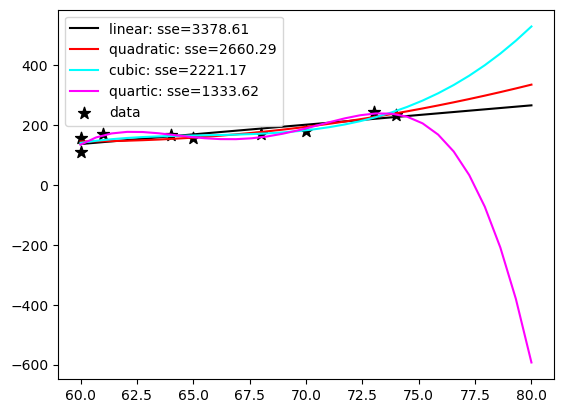

In [7]:
x_plot = np.linspace(60,80,30)
Xones_plot = np.ones(shape=(len(x_plot)))
X1_plot = np.c_[Xones_plot[:],x_plot]
X2_plot = np.c_[Xones_plot[:],x_plot,x_plot**2]
X3_plot = np.c_[Xones_plot[:],x_plot,x_plot**2,x_plot**3]
X4_plot = np.c_[Xones_plot[:],x_plot,x_plot**2,x_plot**3,x_plot**4]

sse1 = np.sum((ytrain-X1@theta_1)**2)
sse2 = np.sum((ytrain-X2@theta_2)**2)
sse3 = np.sum((ytrain-X3@theta_3)**2)
sse4 = np.sum((ytrain-X4@theta_4)**2)

plt.plot(x_plot,X1_plot@theta_1,color='black',label=f'linear: sse={sse1:.2f}')
plt.plot(x_plot,X2_plot@theta_2,color='red',label=f'quadratic: sse={sse2:.2f}')
plt.plot(x_plot,X3_plot@theta_3,color='cyan',label=f'cubic: sse={sse3:.2f}')
plt.plot(x_plot,X4_plot@theta_4,color='magenta',label=f'quartic: sse={sse4:.2f}')
plt.scatter(xtrain,ytrain, s=80, c="black",label='data',marker='*')
plt.legend()
plt.show()

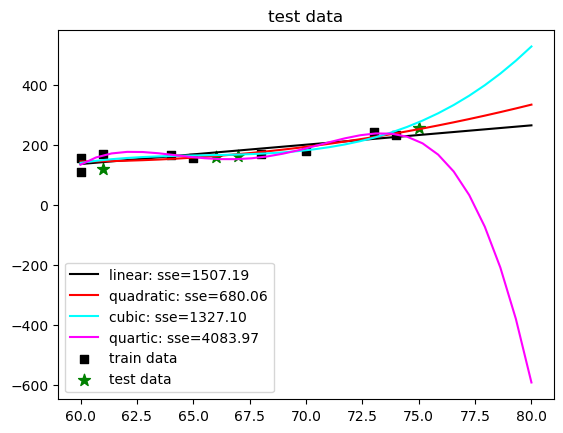

In [8]:
Xonestest = np.ones(shape=(len(xtest)))
X1test = np.c_[Xonestest[:],xtest]
X2test = np.c_[Xonestest[:],xtest,xtest**2]
X3test = np.c_[Xonestest[:],xtest,xtest**2,xtest**3]
X4test = np.c_[Xonestest[:],xtest,xtest**2,xtest**3,xtest**4]

sse1_test = np.sum((ytest-X1test@theta_1)**2)
sse2_test = np.sum((ytest-X2test@theta_2)**2)
sse3_test = np.sum((ytest-X3test@theta_3)**2)
sse4_test = np.sum((ytest-X4test@theta_4)**2)

plt.plot(x_plot,X1_plot@theta_1,color='black',label=f'linear: sse={sse1_test:.2f}')
plt.plot(x_plot,X2_plot@theta_2,color='red',label=f'quadratic: sse={sse2_test:.2f}')
plt.plot(x_plot,X3_plot@theta_3,color='cyan',label=f'cubic: sse={sse3_test:.2f}')
plt.plot(x_plot,X4_plot@theta_4,color='magenta',label=f'quartic: sse={sse4_test:.2f}')
plt.scatter(xtrain,ytrain, s=40, c="black",label='train data',marker='s')
plt.scatter(xtest,ytest, s=80, c="green",label='test data',marker='*')
plt.legend()
plt.title('test data')
plt.show()

# We can also calculate the AIC values for information criteria

In [9]:
aic1 = 2*len(theta_1)-2*np.log(sse1)
aic2 = 2*len(theta_2)-2*np.log(sse2)
aic3 = 2*len(theta_3)-2*np.log(sse3)
aic4 = 2*len(theta_4)-2*np.log(sse4)

print(f"Model 1 {aic1}")
print(f"Model 2 {aic2}")
print(f"Model 3 {aic3}")
print(f"Model 4 {aic4}")


Model 1 -12.250439731407347
Model 2 -9.772380202004694
Model 3 -7.41158096062299
Model 4 -4.391303684250072


# Finally, we can calculate the $R^2$ value for the training data

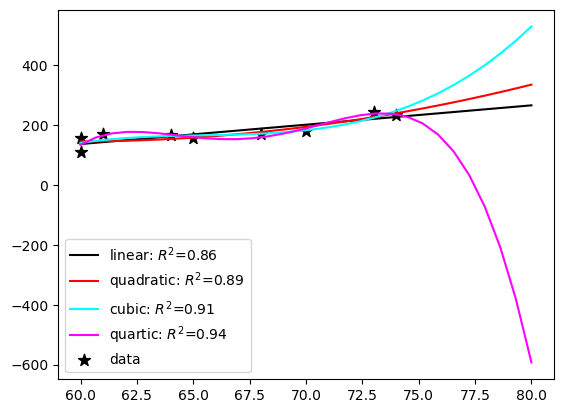

In [10]:
x_plot = np.linspace(60,80,30)
Xones_plot = np.ones(shape=(len(x_plot)))
X1_plot = np.c_[Xones_plot[:],x_plot]
X2_plot = np.c_[Xones_plot[:],x_plot,x_plot**2]
X3_plot = np.c_[Xones_plot[:],x_plot,x_plot**2,x_plot**3]
X4_plot = np.c_[Xones_plot[:],x_plot,x_plot**2,x_plot**3,x_plot**4]

ybar = np.mean(y)
ss_tot = np.sum( (y-ybar)**2)

sse1 = np.sum((ytrain-X1@theta_1)**2)
sse2 = np.sum((ytrain-X2@theta_2)**2)
sse3 = np.sum((ytrain-X3@theta_3)**2)
sse4 = np.sum((ytrain-X4@theta_4)**2)
R2_model1 = 1.0 - sse1/ss_tot
R2_model2 = 1.0 - sse2/ss_tot
R2_model3 = 1.0 - sse3/ss_tot
R2_model4 = 1.0 - sse4/ss_tot

plt.plot(x_plot,X1_plot@theta_1,color='black',label=f'linear: $R^2$={R2_model1:.2f}')
plt.plot(x_plot,X2_plot@theta_2,color='red',label=f'quadratic: $R^2$={R2_model2:.2f}')
plt.plot(x_plot,X3_plot@theta_3,color='cyan',label=f'cubic: $R^2$={R2_model3:.2f}')
plt.plot(x_plot,X4_plot@theta_4,color='magenta',label=f'quartic: $R^2$={R2_model4:.2f}')
plt.scatter(xtrain,ytrain, s=80, c="black",label='data',marker='*')
plt.legend()
plt.show()